<a href="https://colab.research.google.com/github/FeLiXp90/AutomacaoPlataformaEstudante/blob/master/IA_Busca_BFS_EXERCICIOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercícios de algoritmos de Busca usando a biblioteca NetworkX

**Instruções:**

1. Faça uma cópia do notebook e salve em sua área pessoal;
2. Preencha as suas informações abaixo.
3. Em seguida, faça os exercícios.

In [ ]:
# @title Prencha suas informações: { display-mode: "form" }

nome_completo = '<Nome completo>'  # @param {type: "string"}
matricula     = '<Matrícula>'  # @param {type: "string"}

data = '2025-05-16'  # @param {type: "date"}
# @markdown ---

# Atividade Prática: Implementação de Algoritmos de Busca

Nesta atividade prática, vocês irão **implementar algoritmos clássicos de busca em grafos** utilizando Python.

Começaremos com um exemplo de como manipular a biblioteca NetworkX para realizar busca em um grafo simples.

Em seguida, vocês deverão adaptar o código para implementar os algoritmos de busca não informada em Python.

A base será o grafo do mapa da Romênia apresentado anteriormente, mas o foco agora será o desenvolvimento das funções de busca.

## Requisitos obrigatórios

* A implementação deve ser feita utilizando o paradigma de **orientação a objetos (POO)**.
* Crie uma classe principal para representar o grafo e implementar os métodos de busca.
* Os métodos **BFS, DFS, UCS e ID-DFS** devem ser implementados como **métodos de classe em Python**.
* As funções devem seguir as definições discutidas em aula e retornar o caminho encontrado do nó de origem até o nó de destino.

## Material de estudo obrigatório

* Leiam o **Capítulo 3 do livro-texto**, que aborda em detalhes os algoritmos de busca não informada.
* Releiam atentamente os **slides apresentados em aula sobre BFS e DFS**.
* Estudem também os **slides complementares sobre UCS e ID-DFS**, para entender as variações e aprofundar a compreensão dos conceitos.

## Orientações gerais

* Testem suas funções utilizando o grafo do mapa da Romênia.
* Comparar os caminhos retornados por cada algoritmo pode ser uma boa forma de validar a implementação.
* Comentem o código para facilitar a correção e o entendimento da lógica utilizada.

---
---


## Exemplo em um Grafo Simples

In [ ]:
import networkx as nx
import numpy as np

In [ ]:
from collections import deque

In [ ]:
G = nx.Graph()

In [ ]:
G.add_edges_from(
    [
        ('w','x'),
        ('t','x'),
        ('x','u'),
        ('x','m'),
        ('r','y'),
        ('y','m'),
        ('s','q'),
        ('q','t'),
        ('p','r'),
        ('p','q'),
        ('z','w'),
        ('u','z')
    ]
)

In [ ]:
import plotly.graph_objects as go

def plota_grafo(G, titulo=""):
    # Calcular posições dos nós
    pos = nx.spring_layout(G, seed=42)

    # --- ARESTAS ---
    edge_x, edge_y = [], []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])

    edge_trace = go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=0.8, color='#888'),
        hoverinfo='none',
        mode='lines'
    )

    # --- NÓS ---
    node_x, node_y, node_text = [], [], []
    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x)
        node_y.append(y)
        node_text.append(str(node))  # nome do nó

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode='markers+text',
        text=node_text,
        textposition="middle center",   # texto centralizado
        textfont=dict(color="black", size=12),
        hoverinfo='none',
        marker=dict(
            size=30,
            color='lightblue',
            line=dict(width=2, color='darkblue')
        )
    )

    # --- FIGURA FINAL ---
    fig = go.Figure(
        data=[edge_trace, node_trace],
        layout=go.Layout(
            title=titulo,
            title_x=0.5,
            showlegend=False,
            hovermode='closest',
            margin=dict(b=20, l=5, r=5, t=40),
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False)
        )
    )

    fig.show()


In [ ]:
plota_grafo(G)

In [ ]:
s = 's'

In [ ]:
G.nodes()

NodeView(('w', 'x', 't', 'u', 'm', 'r', 'y', 's', 'q', 'p', 'z'))

In [ ]:
G.edges()

EdgeView([('w', 'x'), ('w', 'z'), ('x', 't'), ('x', 'u'), ('x', 'm'), ('t', 'q'), ('u', 'z'), ('m', 'y'), ('r', 'y'), ('r', 'p'), ('s', 'q'), ('q', 'p')])

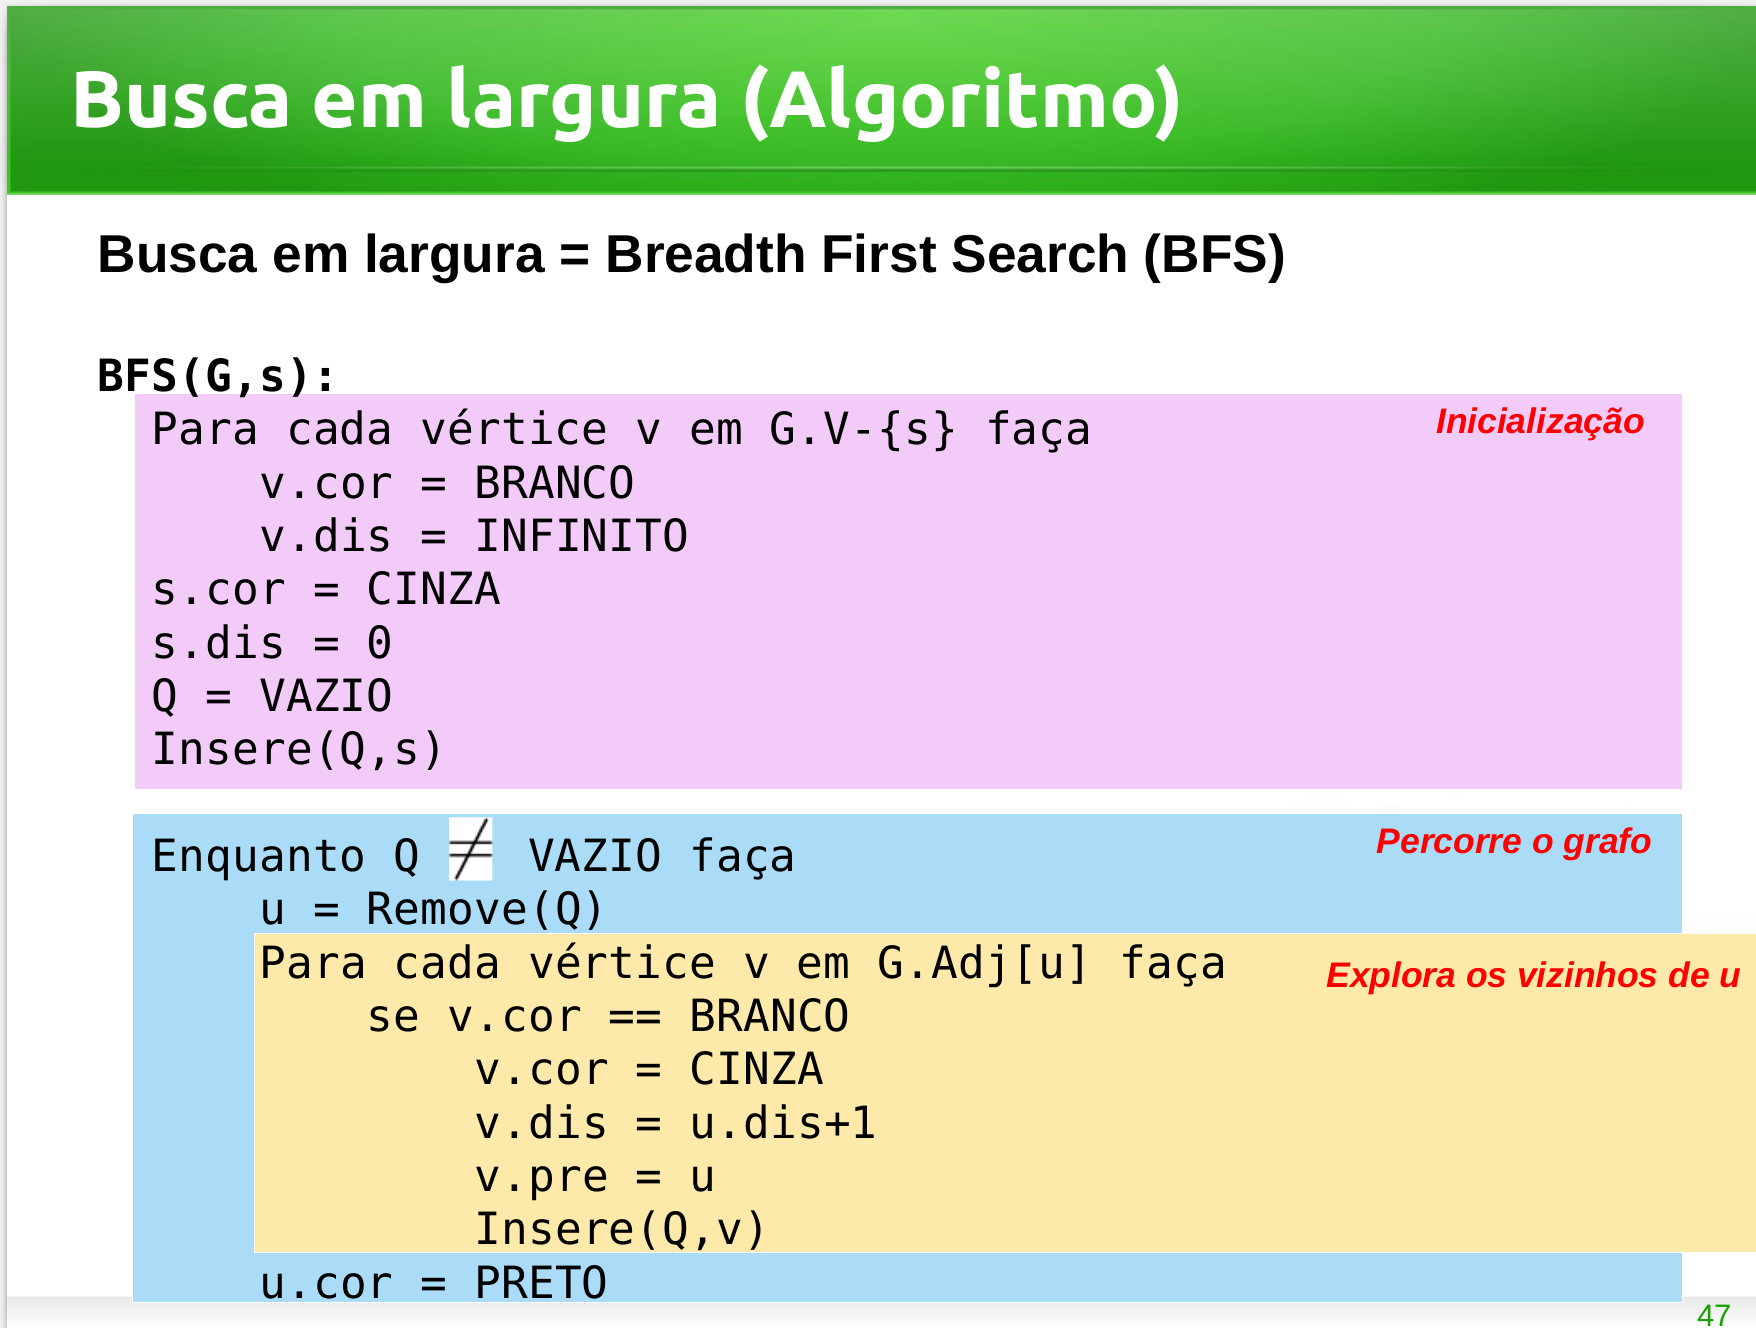

In [ ]:
def BFS(G,s):

    # INICIALIZACAO
    for v in G.nodes() - {s}:
        G.nodes[v]['cor'] = 'branco'
        G.nodes[v]['dis'] = np.inf

    G.nodes[s]['cor'] = 'cinza'
    G.nodes[s]['dis'] = 0

    # Fila (append (right), popleft)
    Q = deque()
    Q.append(s)

    # coloque o restante código
    #

In [ ]:
G.nodes(data=True)

NodeDataView({'v': {'cor': 'branco', 'dis': inf}, 'r': {'cor': 'branco', 'dis': inf}, 's': {'cor': 'cinza', 'dis': 0}, 'w': {'cor': 'branco', 'dis': inf}, 't': {'cor': 'branco', 'dis': inf}, 'x': {'cor': 'branco', 'dis': inf}, 'u': {'cor': 'branco', 'dis': inf}, 'z': {'cor': 'branco', 'dis': inf}})


## Exercícios

A partir dos exemplos acima, faça o que se pede:

1. Implemente a parte azul ("enquanto...") da figura acima.

1. **Busca em Largura (BFS)**
   Implemente a função `bfs(self, origem, destino)` para realizar a busca em largura. Use como referência a estrutura do código discutido em aula. O método deve retornar o caminho encontrado do nó de origem até o nó de destino.

1. Adicione o atributo ¨pre" (predecessor) e implemente a função `caminho_mais_curto`.



In [ ]:
# ---------------------------
# 1. BFS
# ---------------------------
# Coloque seu código aqui

